# Twizzle: R(2+1)D-18 (Kinetics-400 pretrained, torchvision) (Person 2)

Trains, tunes and exports **R(2+1)D-18 (Kinetics-400 pretrained, torchvision)** for the 11-class element classifier. Everything heavy lives in `twizzle_train.py`
(repo root), so this notebook only describes *what* to run and shows the results.

**Model B, the comparison model: a heavier factorised (2+1)D CNN that needs only torchvision. Expect slower epochs and a slower CPU model than X3D; that cost is part of the comparison. Run it on Colab or the second machine while X3D trains.**

## Run order
| Step | What happens | Time |
|---|---|---|
| 0 | `DEV_MODE = True`: tiny end-to-end check on `preprocessed_mini` (downloads pretrained weights, trains 2 epochs per run, exports ONNX) | minutes |
| 1 | `DEV_MODE = False`: data sanity, batch-size probe, speed test | minutes |
| 2 | Experiment stages on a 25% train subset: Baseline, E6 (transfer depth), E1 (learning rate), E3 (augmentation) (E4 optional) | see the printed estimate |
| 3 | Final training of the winning config on the full capped train set | the longest step |
| 4 | Validation report, calibration, CPU latency, ONNX export | minutes |
| 5 | Test evaluation, **once**, with `EVALUATE_TEST = True` | minutes |

**Always run Step 0 first.** The first run in a new environment is where install problems show up (pytorchvideo, ONNX export). Finding them with 143 clips costs minutes; finding them after a 6-hour run does not.

Runs are **resumable**: a configuration that has already been trained (same settings) is loaded from `runs/` instead of being trained again, so you can stop the notebook and start it again.

**Rules from the spec:** never invent numbers; model selection uses *validation* only; the test split is evaluated once at the end; log your AI use in the AI usage table.

## 0. Setup and switches

In [18]:
import os, sys, json, time, copy, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO_ROOT = Path(os.environ.get("TWIZZLE_ROOT", Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()))
sys.path.insert(0, str(REPO_ROOT))
import twizzle_train as T

# ------------------------------------------------------------------ switches
DEV_MODE = False          # True: tiny pipeline check on preprocessed_mini. Set False for the real experiments.
EVALUATE_TEST = True    # keep False until the final model is chosen. The test split may be evaluated ONCE.
RUN_E4 = False          # optimizer comparison (required for X3D, optional for R(2+1)D)
MODEL = "r2plus1d_18"
EXPORT_NAME = "r2plus1d"  # folder name under export/ and prefix of predictions/ files (spec Section 3.3)

# ------------------------------------------------------------------ experiment protocol (spec Section 6.4)
SWEEP_SUBSET = 0.25      # share of the (capped) train split used while comparing settings
SWEEP_EPOCHS = 8
FINAL_EPOCHS = 20
BATCH_SIZE, ACCUM = 8, 2  # effective batch = BATCH_SIZE * ACCUM. Run the probe in Section 2 and adjust.
NUM_WORKERS = 4          # if the DataLoader hangs on Windows, set 0
if DEV_MODE:
    SWEEP_SUBSET, SWEEP_EPOCHS, FINAL_EPOCHS, NUM_WORKERS = 1.0, 2, 2, 0

DATA_ROOT = REPO_ROOT / "dataset" / ("preprocessed_mini" if DEV_MODE else "preprocessed")
SUFFIX = "_dev" if DEV_MODE else ""
RUNS_DIR = REPO_ROOT / "runs" / (MODEL + SUFFIX)
EXPORT_DIR = REPO_ROOT / ("export" + SUFFIX) / EXPORT_NAME
PRED_DIR = REPO_ROOT / ("predictions" + SUFFIX)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

BASE = T.Config(model=MODEL, data_root=str(DATA_ROOT), runs_dir=str(RUNS_DIR), batch_size=BATCH_SIZE, accum_steps=ACCUM,
                epochs=SWEEP_EPOCHS, subset_frac=SWEEP_SUBSET, num_workers=NUM_WORKERS, finetune_mode="frozen",
                lr=1e-3, optimizer="adamw", augmentation="off", early_stop_patience=2 if DEV_MODE else 4)
T.seed_everything(BASE.seed)

print("DEV_MODE:", DEV_MODE, "| data:", DATA_ROOT.name, "| runs:", RUNS_DIR.relative_to(REPO_ROOT))
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      (torch.cuda.get_device_name(0) + f" ({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)") if torch.cuda.is_available() else "(CPU only: use DEV_MODE, real training needs a GPU)")
assert (DATA_ROOT / "labels.csv").is_file(), f"{DATA_ROOT} has no labels.csv: run the preprocessing notebook first (or copy the folder)"

DEV_MODE: False | data: preprocessed | runs: runs/r2plus1d_18
torch 2.14.1+cu130 | cuda: True NVIDIA GeForce RTX 5060 Laptop GPU (8.5 GB)


## 1. Data sanity check

Before any training: do the tensors have the contract shape, are they normalised with **this model's** mean/std, and does augmentation look sensible? One wrong normalisation constant silently costs accuracy, so we look.

split,train,val,test
label_name,,,
Toeloop,1116,240,240
Salchow,428,92,93
Flip,646,138,138
Loop,438,95,93
Lutz,671,144,144
Axel,904,193,193
CamelSpin,1500,373,373
SitSpin,1500,394,395
UprightSpin,1497,320,321


sample: (3, 16, 160, 160) torch.float32 label 3 Loop
normalised values: mean 0.56, std 1.29 (should be roughly 0 and 1 after the model-specific normalisation)


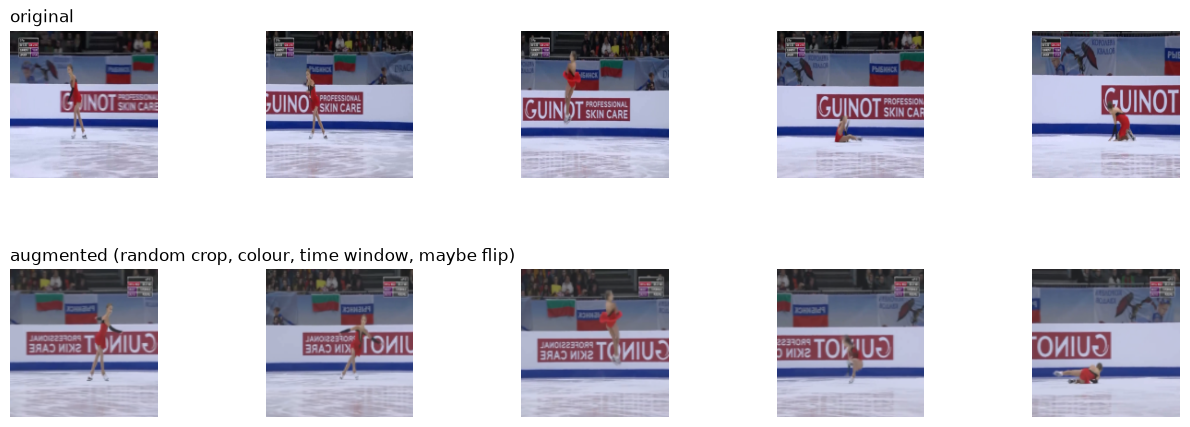

In [19]:
lab = pd.read_csv(DATA_ROOT / "labels.csv")
counts = pd.crosstab(lab.label_name, lab.split).reindex(T.CLASS_NAMES)[["train", "val", "test"]]
display(counts)

ds = T.ClipDataset(str(DATA_ROOT), "train", BASE)
x, y = ds[0]
print("sample:", tuple(x.shape), x.dtype, "label", y, T.CLASS_NAMES[y])
assert tuple(x.shape) == (3, 16, 160, 160) and x.dtype == torch.float32, "tensor does not match the data contract"
print(f"normalised values: mean {x.mean():.2f}, std {x.std():.2f} (should be roughly 0 and 1 after the model-specific normalisation)")

aug_cfg = T.apply_overrides(BASE, {"augmentation": "basic_flip"}, "viz")
aug_ds = T.ClipDataset(str(DATA_ROOT), "train", aug_cfg)
stats = T.MODEL_STATS[MODEL]
mean = torch.tensor(stats["mean"]).view(3, 1, 1, 1); std = torch.tensor(stats["std"]).view(3, 1, 1, 1)
def to_img(t, f):
    return (t * std + mean).clamp(0, 1)[:, f].permute(1, 2, 0).numpy()
xa, _ = aug_ds[0]
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for j, f in enumerate(np.linspace(0, 15, 5).astype(int)):
    ax[0, j].imshow(to_img(x, f)); ax[0, j].axis("off"); ax[1, j].imshow(to_img(xa, f)); ax[1, j].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("augmented (random crop, colour, time window, maybe flip)", loc="left")
plt.tight_layout(); plt.show()

In [20]:
# ---- forward-pass check: does the model accept our clips and return 11 raw logits (not probabilities)?
net, head = T.build_model(BASE)
T.apply_finetune_mode(net, head, BASE)
total_p, train_p = T.count_params(net)
net.eval()
with torch.no_grad():
    out = net(x.unsqueeze(0))
print(f"{MODEL}: input (1,3,16,160,160) -> output {tuple(out.shape)} | params {total_p/1e6:.1f}M, trainable in 'frozen' mode {train_p/1e6:.3f}M")
assert tuple(out.shape) == (1, 11), "model output is not (1, 11): the classifier head was not replaced correctly"
if bool((out >= 0).all()) and abs(float(out.sum()) - 1.0) < 1e-3:
    raise AssertionError("output looks like probabilities (softmax still inside the model): logits are required")
print("raw logits:", np.round(out[0].numpy(), 2))
del net, head

r2plus1d_18: input (1,3,16,160,160) -> output (1, 11) | params 31.3M, trainable in 'frozen' mode 0.006M
raw logits: [-0.77  1.24  0.09 -0.73  0.28 -0.05  0.52  0.03  0.78  0.84 -0.34]


## 2. Batch size and speed

The GPU has limited memory. `probe_batch_size` finds the largest batch that fits for **full** fine-tuning (the worst case). Use that as `BATCH_SIZE` and raise `ACCUM` so that `BATCH_SIZE * ACCUM` stays around 16. The speed test trains one epoch on 10% of the data so you can *measure* how long the real runs will take instead of guessing. The estimate below is rough (unfrozen layers are slower than frozen ones, hence the factor).

In [21]:
best_bs = T.probe_batch_size(BASE)
print("largest batch that fits:", best_bs, "(current BATCH_SIZE =", BATCH_SIZE, ")")

speed_cfg = T.apply_overrides(BASE, {"subset_frac": 0.1, "epochs": 1}, "speedtest")
sp = T.train_run(speed_cfg, force=True)
full_epoch_s = sp["sec_per_epoch"] / 0.1
n_runs = 8 if RUN_E4 else 7
sweep_min = n_runs * SWEEP_EPOCHS * full_epoch_s * SWEEP_SUBSET * 2.0 / 60
final_min = FINAL_EPOCHS * full_epoch_s * 2.0 / 60
print(f"\none FULL epoch on frozen layers ~ {full_epoch_s:.0f}s   (measured on a 10% subset)")
print(f"rough estimate (x2 for unfrozen layers): sweep ~ {sweep_min:.0f} min for ~{n_runs} runs, final training ~ {final_min:.0f} min")

  batch  4: fits, peak 3.2 GB
  batch  8: fits, peak 5.3 GB
  batch 12: fits, peak 7.4 GB
  batch 16: fits, peak 9.4 GB
  batch 24: fits, peak 13.5 GB


[W1111 12:36:22.463792690 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1388314624 bytes (free: 0, total: 8546484224).
[W1111 12:37:54.132981845 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1365245952 bytes (free: 0, total: 8546484224).


  batch 32: fits, peak 17.7 GB
largest batch that fits: 32 (current BATCH_SIZE = 8 )
[speedtest] r2plus1d_18 | mode=frozen opt=adamw lr=0.001 aug=off | train 1066 val 3000 | params 31.3M (trainable 0.01M) | device=cuda amp=True
  epoch  1/1 train_loss 2.584 val_loss 2.202 acc 0.332 macroF1 0.139 jumpF1 0.071 (64s)
[speedtest] best epoch 1: val macro-F1 0.139, jump macro-F1 0.071, acc 0.332

one FULL epoch on frozen layers ~ 644s   (measured on a 10% subset)
rough estimate (x2 for unfrozen layers): sweep ~ 301 min for ~7 runs, final training ~ 429 min


## 3. Experiments

Each stage trains a few variants, **picks the best by validation macro-F1**, and carries it forward (`BEST`). Identical configurations are never trained twice, so the winner of one stage is reused in the next.

* **Baseline:** pretrained backbone frozen, only the new classifier is trained, default settings.
* **E6 transfer depth:** classifier only / + last stage / everything.
* **E1 learning rate:** 0.3x, 1x and 3x of the winner's learning rate.
* **E3 augmentation:** off / crop + colour + time window / the same + horizontal flip. The flip reverses the rotation direction of a jump, so it is tested, not assumed.
* **E4 optimizer:** AdamW vs SGD with momentum.

For every stage write down *what changed, why, and what effect it had* (brief Section 10): the tables below are the evidence.

[baseline] r2plus1d_18 | mode=frozen opt=adamw lr=0.001 aug=off | train 2663 val 3000 | params 31.3M (trainable 0.01M) | device=cuda amp=True
  epoch  1/8 train_loss 2.508 val_loss 2.022 acc 0.429 macroF1 0.190 jumpF1 0.067 (89s)
  epoch  2/8 train_loss 2.248 val_loss 1.832 acc 0.464 macroF1 0.263 jumpF1 0.097 (89s)
  epoch  3/8 train_loss 2.123 val_loss 1.711 acc 0.436 macroF1 0.239 jumpF1 0.064 (89s)
  epoch  4/8 train_loss 2.051 val_loss 1.528 acc 0.573 macroF1 0.330 jumpF1 0.182 (89s)
  epoch  5/8 train_loss 2.005 val_loss 1.601 acc 0.547 macroF1 0.378 jumpF1 0.200 (89s)
  epoch  6/8 train_loss 1.974 val_loss 1.582 acc 0.510 macroF1 0.351 jumpF1 0.206 (89s)
  epoch  7/8 train_loss 1.950 val_loss 1.548 acc 0.575 macroF1 0.391 jumpF1 0.211 (89s)
  epoch  8/8 train_loss 1.958 val_loss 1.540 acc 0.577 macroF1 0.396 jumpF1 0.214 (89s)
[baseline] best epoch 8: val macro-F1 0.396, jump macro-F1 0.214, acc 0.577


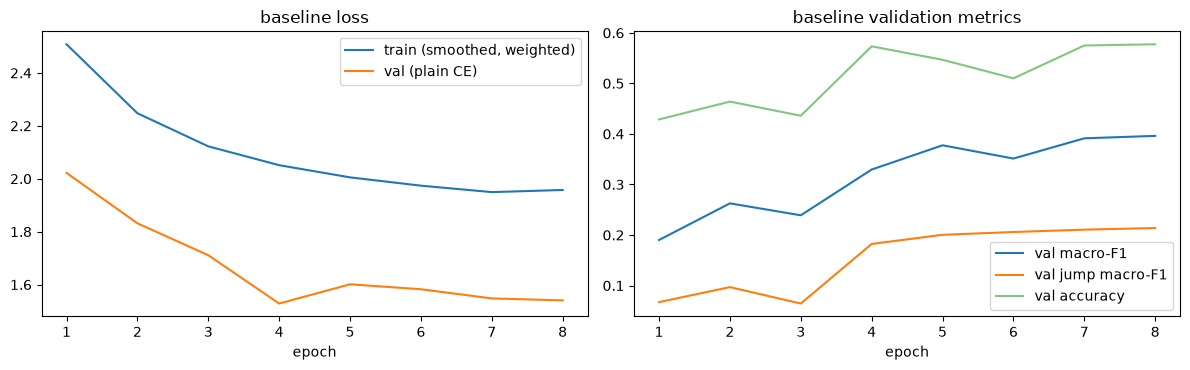

In [22]:
baseline = T.train_run(T.apply_overrides(BASE, {}, "baseline"))
T.plot_history(baseline["history"], "baseline")

In [23]:
# ---- E6: transfer-learning depth (lr differs per mode because a larger trainable part needs a smaller step)
E6 = {"frozen":  {"finetune_mode": "frozen",  "lr": 1e-3},
      "partial": {"finetune_mode": "partial", "lr": 3e-4},
      "full":    {"finetune_mode": "full",    "lr": 1e-4}}
best_e6, ov_e6, tab_e6 = T.run_stage(BASE, E6, "e6_depth")
BEST = dict(ov_e6)            # settings carried forward
display(tab_e6)

[reuse] 'e6_depth_frozen' uses identical run 'baseline' | val macro-F1 0.396
Checkpoint available: /mnt/c/Users/Kenzie/Downloads/Deep Learning/runs/r2plus1d_18/e6_depth_frozen/best.pt
[e6_depth_partial] r2plus1d_18 | mode=partial opt=adamw lr=0.0003 aug=off | train 2663 val 3000 | params 31.3M (trainable 23.50M) | device=cuda amp=True
  epoch  1/8 train_loss 2.038 val_loss 0.915 acc 0.693 macroF1 0.490 jumpF1 0.210 (93s)
  epoch  2/8 train_loss 1.568 val_loss 0.945 acc 0.694 macroF1 0.514 jumpF1 0.313 (93s)
  epoch  3/8 train_loss 1.277 val_loss 0.784 acc 0.759 macroF1 0.612 jumpF1 0.431 (93s)
  epoch  4/8 train_loss 1.009 val_loss 0.655 acc 0.810 macroF1 0.675 jumpF1 0.498 (93s)
  epoch  5/8 train_loss 0.802 val_loss 0.685 acc 0.821 macroF1 0.686 jumpF1 0.507 (93s)
  epoch  6/8 train_loss 0.726 val_loss 0.640 acc 0.829 macroF1 0.698 jumpF1 0.518 (93s)
  epoch  7/8 train_loss 0.703 val_loss 0.637 acc 0.833 macroF1 0.701 jumpF1 0.526 (93s)
  epoch  8/8 train_loss 0.697 val_loss 0.634 ac

,variant,finetune_mode,lr,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,frozen,frozen,0.0010,0.396141,0.213802,0.577333,89.1
1,partial,partial,0.0003,0.705044,0.532712,0.833667,93.1
2,full,full,0.0001,0.771636,0.630919,0.871000,172.1


In [24]:
# ---- E1: learning rate around the E6 winner
lr0 = BEST["lr"]
E1 = {f"x{k}": {**BEST, "lr": lr0 * k} for k in (0.3, 1, 3)}
best_e1, ov_e1, tab_e1 = T.run_stage(BASE, E1, "e1_lr")
BEST.update(ov_e1)
display(tab_e1)

[e1_lr_x0.3] r2plus1d_18 | mode=full opt=adamw lr=3e-05 aug=off | train 2663 val 3000 | params 31.3M (trainable 31.31M) | device=cuda amp=True
  epoch  1/8 train_loss 2.436 val_loss 1.433 acc 0.605 macroF1 0.397 jumpF1 0.166 (172s)
  epoch  2/8 train_loss 1.766 val_loss 0.944 acc 0.724 macroF1 0.532 jumpF1 0.290 (172s)
  epoch  3/8 train_loss 1.494 val_loss 0.906 acc 0.733 macroF1 0.572 jumpF1 0.341 (172s)
  epoch  4/8 train_loss 1.233 val_loss 0.752 acc 0.796 macroF1 0.674 jumpF1 0.478 (172s)
  epoch  5/8 train_loss 1.025 val_loss 0.681 acc 0.811 macroF1 0.682 jumpF1 0.494 (172s)
  epoch  6/8 train_loss 0.919 val_loss 0.693 acc 0.809 macroF1 0.686 jumpF1 0.501 (172s)
  epoch  7/8 train_loss 0.874 val_loss 0.664 acc 0.818 macroF1 0.695 jumpF1 0.508 (172s)
  epoch  8/8 train_loss 0.848 val_loss 0.668 acc 0.816 macroF1 0.692 jumpF1 0.513 (172s)
[e1_lr_x0.3] best epoch 7: val macro-F1 0.695, jump macro-F1 0.508, acc 0.818
[reuse] 'e1_lr_x1' uses identical run 'e6_depth_full' | val macro-F

,variant,finetune_mode,lr,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,x0.3,full,0.00003,0.694645,0.507989,0.818000,172.1
1,x1,full,0.00010,0.771636,0.630919,0.871000,172.1
2,x3,full,0.00030,0.776530,0.648617,0.873333,172.1


In [25]:
# ---- E3: data augmentation (including the horizontal-flip ablation)
E3 = {name: {**BEST, "augmentation": name} for name in ("off", "basic", "basic_flip")}
best_e3, ov_e3, tab_e3 = T.run_stage(BASE, E3, "e3_aug")
BEST.update(ov_e3)
display(tab_e3)

[reuse] 'e3_aug_off' uses identical run 'e1_lr_x3' | val macro-F1 0.777
Checkpoint available: /mnt/c/Users/Kenzie/Downloads/Deep Learning/runs/r2plus1d_18/e3_aug_off/best.pt
[e3_aug_basic] r2plus1d_18 | mode=full opt=adamw lr=0.0003 aug=basic | train 2663 val 3000 | params 31.3M (trainable 31.31M) | device=cuda amp=True
  epoch  1/8 train_loss 2.072 val_loss 0.977 acc 0.680 macroF1 0.475 jumpF1 0.191 (172s)
  epoch  2/8 train_loss 1.707 val_loss 0.879 acc 0.697 macroF1 0.510 jumpF1 0.284 (172s)
  epoch  3/8 train_loss 1.513 val_loss 0.786 acc 0.748 macroF1 0.583 jumpF1 0.391 (172s)
  epoch  4/8 train_loss 1.326 val_loss 0.738 acc 0.786 macroF1 0.658 jumpF1 0.549 (172s)
  epoch  5/8 train_loss 1.140 val_loss 0.680 acc 0.813 macroF1 0.706 jumpF1 0.570 (172s)
  epoch  6/8 train_loss 1.003 val_loss 0.509 acc 0.864 macroF1 0.767 jumpF1 0.651 (172s)
  epoch  7/8 train_loss 0.896 val_loss 0.496 acc 0.868 macroF1 0.776 jumpF1 0.658 (172s)
  epoch  8/8 train_loss 0.829 val_loss 0.477 acc 0.873 

,variant,finetune_mode,lr,augmentation,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,off,full,0.0003,off,0.776530,0.648617,0.873333,172.1
1,basic,full,0.0003,basic,0.782594,0.672252,0.873000,171.9
2,basic_flip,full,0.0003,basic_flip,0.778512,0.660286,0.869667,171.9


In [26]:
# ---- E4: optimizer (SGD gets a 10x larger lr, the usual ratio between SGD and Adam-type optimizers)
if RUN_E4:
    E4 = {"adamw": {**BEST, "optimizer": "adamw"}, "sgd": {**BEST, "optimizer": "sgd", "lr": BEST["lr"] * 10}}
    best_e4, ov_e4, tab_e4 = T.run_stage(BASE, E4, "e4_opt")
    BEST.update(ov_e4)
    display(tab_e4)
else:
    print("RUN_E4 is False: skipped (optional for this model). Carried-forward optimizer:", BEST.get("optimizer", "adamw"))
print("\nCarried-forward settings:", BEST)

RUN_E4 is False: skipped (optional for this model). Carried-forward optimizer: adamw

Carried-forward settings: {'finetune_mode': 'full', 'lr': 0.00030000000000000003, 'augmentation': 'basic'}


,run,mode,opt,lr,aug,subset,epochs_cfg,best_epoch,val_macro_f1,val_jump_f1,val_acc,sec/epoch,trainable_M
4,e3_aug_basic,full,adamw,0.00030,basic,0.25,8,8,0.7826,0.6723,0.8730,171.9,31.31
5,e3_aug_basic_flip,full,adamw,0.00030,basic_flip,0.25,8,8,0.7785,0.6603,0.8697,171.9,31.31
3,e1_lr_x3,full,adamw,0.00030,off,0.25,8,8,0.7765,0.6486,0.8733,172.1,31.31
6,e3_aug_off,full,adamw,0.00030,off,0.25,8,8,0.7765,0.6486,0.8733,172.1,31.31
2,e1_lr_x1,full,adamw,0.00010,off,0.25,8,7,0.7716,0.6309,0.8710,172.1,31.31
8,e6_depth_full,full,adamw,0.00010,off,0.25,8,7,0.7716,0.6309,0.8710,172.1,31.31
9,e6_depth_partial,partial,adamw,0.00030,off,0.25,8,8,0.7050,0.5327,0.8337,93.1,23.50
1,e1_lr_x0.3,full,adamw,0.00003,off,0.25,8,7,0.6946,0.5080,0.8180,172.1,31.31
0,baseline,frozen,adamw,0.00100,off,0.25,8,8,0.3961,0.2138,0.5773,89.1,0.01
7,e6_depth_frozen,frozen,adamw,0.00100,off,0.25,8,8,0.3961,0.2138,0.5773,89.1,0.01


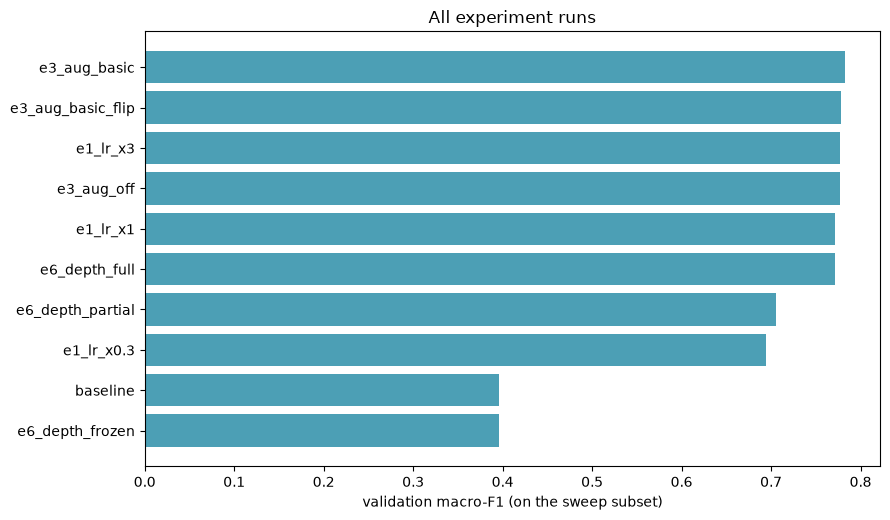

In [27]:
runs_df = T.summarize_runs(RUNS_DIR)
runs_df = runs_df[runs_df.run != "speedtest"].sort_values("val_macro_f1", ascending=False)
runs_df.to_csv(RUNS_DIR / "sweep_summary.csv", index=False)
display(runs_df)

fig, ax = plt.subplots(figsize=(9, 0.38 * len(runs_df) + 1.5))
ax.barh(runs_df.run[::-1], runs_df.val_macro_f1[::-1], color="#4C9FB5")
ax.set_xlabel("validation macro-F1 (on the sweep subset)"); ax.set_title("All experiment runs")
plt.tight_layout(); plt.show()

## 4. Final training

The winning configuration is retrained from scratch on the **full** capped train split with more epochs. Early stopping watches validation macro-F1 and the best epoch is kept.

[final] r2plus1d_18 | mode=full opt=adamw lr=0.0003 aug=basic | train 10650 val 3000 | params 31.3M (trainable 31.31M) | device=cuda amp=True
  epoch  1/20 train_loss 1.804 val_loss 0.818 acc 0.781 macroF1 0.624 jumpF1 0.431 (548s)
  epoch  2/20 train_loss 1.404 val_loss 0.790 acc 0.777 macroF1 0.669 jumpF1 0.528 (548s)
  epoch  3/20 train_loss 1.223 val_loss 0.509 acc 0.861 macroF1 0.752 jumpF1 0.619 (548s)
  epoch  4/20 train_loss 1.141 val_loss 0.533 acc 0.855 macroF1 0.766 jumpF1 0.639 (548s)
  epoch  5/20 train_loss 1.073 val_loss 0.453 acc 0.885 macroF1 0.783 jumpF1 0.651 (548s)
  epoch  6/20 train_loss 1.005 val_loss 0.392 acc 0.902 macroF1 0.831 jumpF1 0.735 (548s)
  epoch  7/20 train_loss 0.946 val_loss 0.429 acc 0.901 macroF1 0.836 jumpF1 0.770 (547s)
  epoch  8/20 train_loss 0.922 val_loss 0.364 acc 0.923 macroF1 0.861 jumpF1 0.790 (547s)
  epoch  9/20 train_loss 0.875 val_loss 0.392 acc 0.910 macroF1 0.850 jumpF1 0.777 (547s)
  epoch 10/20 train_loss 0.827 val_loss 0.364 ac

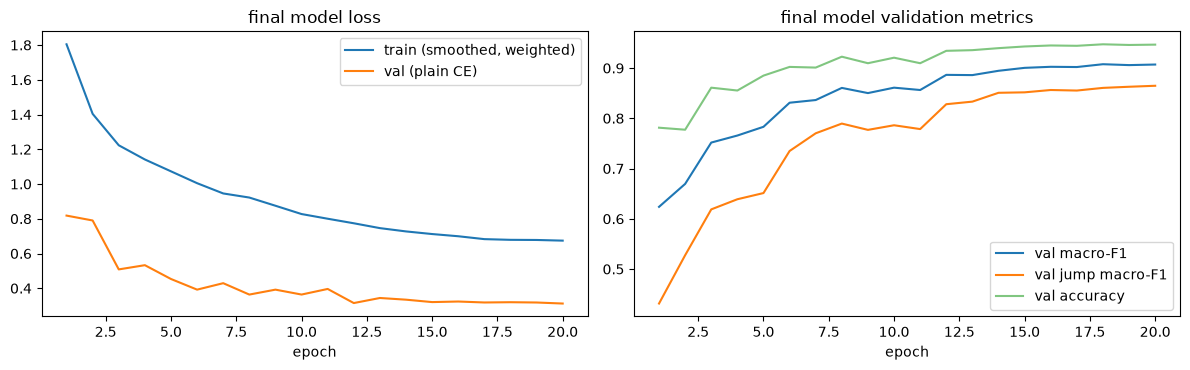

train time 183.5 min | 548s/epoch | peak VRAM 4.807225856


In [28]:
final_cfg = T.apply_overrides(BASE, {**BEST, "subset_frac": 1.0, "epochs": FINAL_EPOCHS}, "final")
final = T.train_run(final_cfg)
FINAL_CKPT = RUNS_DIR / "final" / "best.pt"
T.plot_history(final["history"], "final model")
print(f"train time {final['train_seconds']/60:.1f} min | {final['sec_per_epoch']:.0f}s/epoch | peak VRAM {final['peak_vram_gb']}")

## 5. Validation report

Read this as an analyst, not as a scoreboard. Which classes are weak? Are the errors the physically plausible ones (Flip vs Lutz share the take-off edge, which is barely visible)? Is there a gap between train and validation loss (overfitting) or are both still falling (underfitting)? Write the answers in your own words in the report.

VAL  accuracy 0.947 | macro-F1 0.908 | jump macro-F1 0.861   <- headline: jump macro-F1


,class,val_F1,val_clips
0,Toeloop,0.898,240
1,Salchow,0.862,92
2,Flip,0.754,138
3,Loop,0.891,95
4,Lutz,0.792,144
5,Axel,0.967,193
6,CamelSpin,0.989,373
7,SitSpin,0.985,394
8,UprightSpin,0.965,320
9,NoBasic,0.891,96


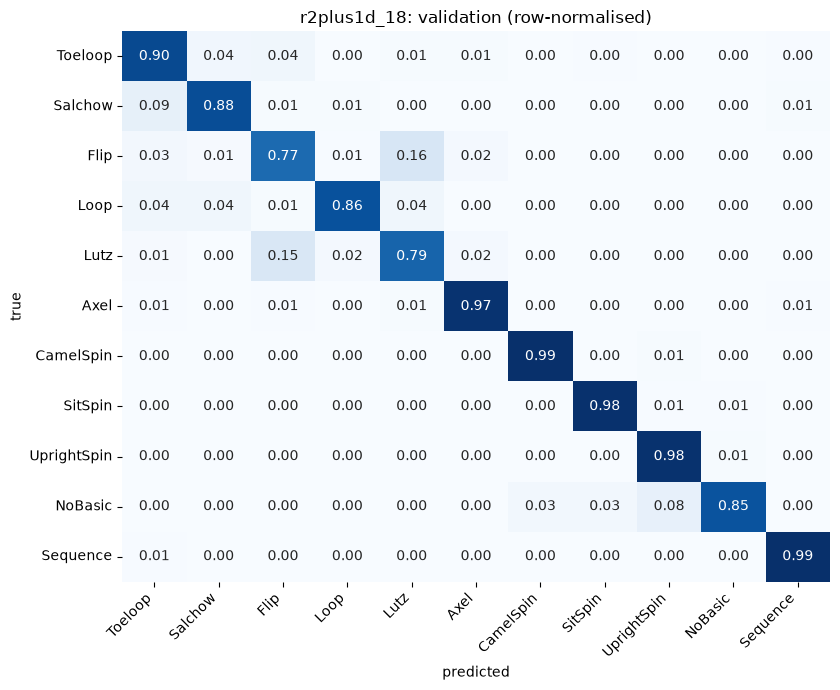

most frequent confusions (true, predicted, count):
          Flip -> Lutz         22
          Lutz -> Flip         22
       Toeloop -> Flip         10
       Toeloop -> Salchow      9
       Salchow -> Toeloop      8
       NoBasic -> UprightSpin  8


In [29]:
val = T.evaluate_split(final_cfg, FINAL_CKPT, "val")
m = val["metrics"]
print(f"VAL  accuracy {m['acc']:.3f} | macro-F1 {m['macro_f1']:.3f} | jump macro-F1 {m['jump_macro_f1']:.3f}   <- headline: jump macro-F1")
display(pd.DataFrame({"class": T.CLASS_NAMES, "val_F1": np.round(m["per_class_f1"], 3),
                      "val_clips": val["confusion"].sum(axis=1)}))
T.plot_confusion(val["confusion"], f"{MODEL}: validation (row-normalised)")
print("most frequent confusions (true, predicted, count):")
for t_, p_, n_ in T.top_confusions(val["confusion"]):
    print(f"  {t_:>12} -> {p_:<12} {n_}")

## 6. Calibration, latency and export for the web app

* **Temperature scaling** (fitted on validation only) makes the probabilities honest: a 90% prediction should be right about 90% of the time.
* **Ambiguity margin:** if (top-1 minus top-2 probability) is below this value the app shows two classes ("Flip or Lutz?"). It is chosen on validation as the smallest margin whose confident predictions reach 95% accuracy.
* **CPU latency** is measured with 2 threads (the size of a free Hugging Face CPU Space). Treat it as the deployment cost of this model.
* **ONNX export** and a parity check against PyTorch. `deployment_meta.json` is what Person 3 reads; nothing is hard-coded in the app.

In [30]:
temperature = T.fit_temperature(val["logits"], val["labels"])
val_probs = T.softmax_np(val["logits"], temperature)
margin, margin_table = T.choose_ambiguity_margin(val_probs, val["labels"], target_acc=0.95)
print(f"temperature {temperature:.3f} | ambiguity margin {margin:.2f}")
display(margin_table.iloc[::2].round(3))

lat = T.benchmark_cpu_latency(final_cfg)
print(f"CPU latency per clip ({lat['threads']} threads): median {lat['cpu_ms_median']:.0f} ms, p90 {lat['cpu_ms_p90']:.0f} ms")

exp = T.export_onnx(final_cfg, FINAL_CKPT, EXPORT_DIR / "model.onnx")
print("ONNX:", exp)
assert exp.get("parity_ok") in (True, None), "ONNX output differs from PyTorch: do NOT hand this model to Person 3"
shutil.copy(FINAL_CKPT, EXPORT_DIR / "weights.pt")

meta = T.write_deployment_meta(EXPORT_DIR / "deployment_meta.json", EXPORT_NAME, final_cfg, temperature, margin,
                               m["macro_f1"], m["jump_macro_f1"],
                               extra={**lat, **exp, "params_total": final["params_total"], "train_seconds": final["train_seconds"],
                                      "dev_mode": DEV_MODE})

PRED_DIR.mkdir(parents=True, exist_ok=True)
np.savez(PRED_DIR / f"{EXPORT_NAME}_val.npz", probs=T.softmax_np(val["logits"]), probs_calibrated=val_probs,
         logits=val["logits"], labels=val["labels"], clip_ids=val["clip_ids"], temperature=np.array(temperature))
print("wrote", EXPORT_DIR.relative_to(REPO_ROOT), "and", (PRED_DIR / f"{EXPORT_NAME}_val.npz").relative_to(REPO_ROOT))

temperature 0.686 | ambiguity margin 0.15


,margin,coverage,acc_confident
0,0.0,1.000,0.947
2,0.1,0.995,0.950
4,0.2,0.987,0.952
6,0.3,0.982,0.955
8,0.4,0.978,0.957
10,0.5,0.971,0.960
12,0.6,0.968,0.961
14,0.7,0.961,0.964
16,0.8,0.951,0.968
18,0.9,0.927,0.976


CPU latency per clip (2 threads): median 1387 ms, p90 1433 ms
ONNX: {'onnx_path': '/mnt/c/Users/Kenzie/Downloads/Deep Learning/export/r2plus1d/model.onnx', 'onnx_mb': 125.2, 'opset': 17, 'export_strategy': 'classic exporter, dynamic batch', 'dynamic_batch': True, 'swish_replaced': 0, 'max_abs_diff_vs_pytorch': 2.980232238769531e-07, 'parity_ok': True}
wrote export/r2plus1d and predictions/r2plus1d_val.npz


## 7. Test evaluation (once)

Set `EVALUATE_TEST = True` **only after** the final model is fixed. Looking at test results and then changing the model turns the test split into a second validation split, and the reported numbers stop being honest. If you must change something after seeing the test score, say so in the report.

TEST accuracy 0.946 | macro-F1 0.903 | jump macro-F1 0.861


,class,test_F1,test_clips
0,Toeloop,0.911,240
1,Salchow,0.814,93
2,Flip,0.770,138
3,Loop,0.874,93
4,Lutz,0.828,144
5,Axel,0.966,193
6,CamelSpin,0.989,373
7,SitSpin,0.979,395
8,UprightSpin,0.955,321
9,NoBasic,0.848,96


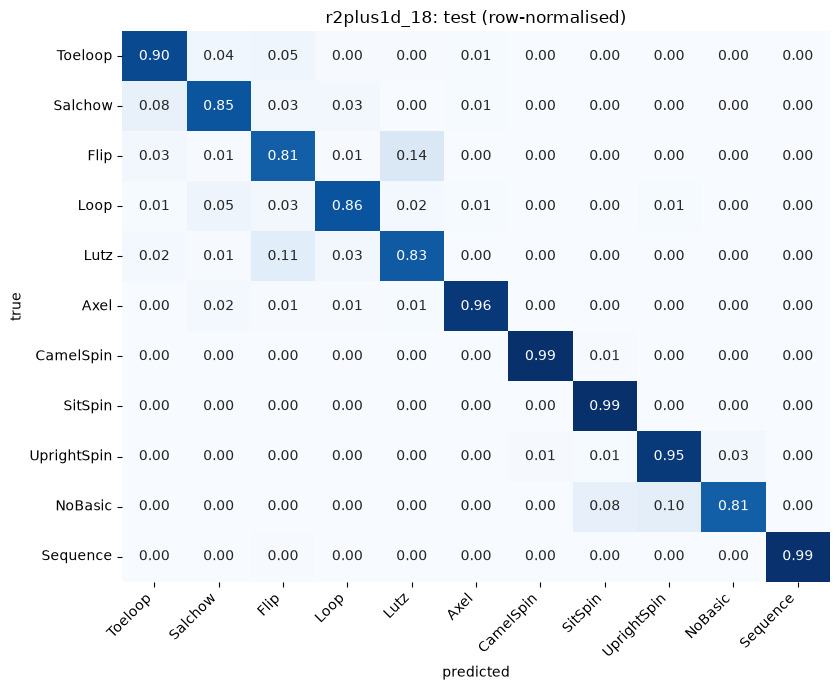

In [25]:
if EVALUATE_TEST:
    test = T.evaluate_split(final_cfg, FINAL_CKPT, "test")
    mt = test["metrics"]
    print(f"TEST accuracy {mt['acc']:.3f} | macro-F1 {mt['macro_f1']:.3f} | jump macro-F1 {mt['jump_macro_f1']:.3f}")
    display(pd.DataFrame({"class": T.CLASS_NAMES, "test_F1": np.round(mt["per_class_f1"], 3), "test_clips": test["confusion"].sum(axis=1)}))
    T.plot_confusion(test["confusion"], f"{MODEL}: test (row-normalised)")
    np.savez(PRED_DIR / f"{EXPORT_NAME}_test.npz", probs=T.softmax_np(test["logits"]),
             probs_calibrated=T.softmax_np(test["logits"], temperature), logits=test["logits"], labels=test["labels"],
             clip_ids=test["clip_ids"], temperature=np.array(temperature))
    (RUNS_DIR / "test_metrics.json").write_text(json.dumps(mt, indent=2))
else:
    print("EVALUATE_TEST is False: test split not touched.")

## 8. Facts for the report

Everything below was measured by this notebook, so it can go into the report. Copy the *numbers*, write the *interpretation* yourself.

In [32]:
facts = {"model": MODEL, "dev_mode": DEV_MODE, "best_settings": BEST, "final_epochs_run": len(final["history"]),
         "best_epoch": final["best_epoch"], "val_macro_f1": m["macro_f1"], "val_jump_macro_f1": m["jump_macro_f1"],
         "val_acc": m["acc"], "params_total_M": round(final["params_total"] / 1e6, 2),
         "train_minutes": round(final["train_seconds"] / 60, 1), "sec_per_epoch": round(final["sec_per_epoch"], 1),
         "peak_vram_gb": final["peak_vram_gb"], "cpu_ms_median_2threads": round(lat["cpu_ms_median"], 0),
         "onnx_mb": exp["onnx_mb"], "temperature": temperature, "ambiguity_margin": margin}
(RUNS_DIR / "report_facts.json").write_text(json.dumps(facts, indent=2, default=str))
display(pd.Series(facts).to_frame("value"))
if DEV_MODE:
    print("\nDEV_MODE results are from a 143-clip pipeline check: they are NOT results. Set DEV_MODE = False and run the real experiments.")

,value
model,r2plus1d_18
dev_mode,False
best_settings,"{'finetune_mode': 'full', 'lr': 0.000300000000..."
final_epochs_run,20
best_epoch,18
val_macro_f1,0.907686
val_jump_macro_f1,0.860568
val_acc,0.947333
params_total_M,31.31
train_minutes,183.5


### Still on your list
1. Run the whole notebook once with `DEV_MODE = True`, fix any install problem, then run it for real.
2. In the report: for each experiment state *what changed, why, and the effect* (use the stage tables); discuss over/underfitting from the loss curves; discuss the confusion matrix; state the trade-off between accuracy and CPU latency.
3. Tell Person 3 when `export/r2plus1d/` is final; tell the team which model you recommend to deploy and why.
4. Log every AI use in the AI usage table, including mistakes you found.